<a href="https://colab.research.google.com/github/erickcorrea3092/Cheminformatics-course/blob/main/3_2_Fingerprints_con_RDkit_(similitud)_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ANTECEDENTES

Primero instalamos la libreria RDKit

In [1]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 57.3 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import seaborn as sn
#---------------------- RDKit packages
from rdkit.Chem import AllChem
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import Draw
from rdkit import DataStructs
from rdkit.ML.Cluster import Butina
#------------------- progress bar
from tqdm import tqdm
#------------------- hide warning
import warnings
warnings.filterwarnings('ignore')

In [3]:
#Cargamos las datos de una dirección de git hub
dataset = pd.read_csv('https://raw.githubusercontent.com/gashawmg/HOMO-LUMO-Enegry-gap-Prediction/master/Orbital_Energies_input_data.csv')
dataset.head(10) #vemos los primeros diez datos

,SMILES,Energygap
0,Cc1ccc(cc1)C(F)(F)F,197.749421
1,OC(=O)CCCCl,247.493942
2,CC(C)(Oc1ccc(CCNC(=O)c2ccc(Cl)cc2)cc1)C(=O)O,164.712327
3,Nc1ccc(Cl)c(Cl)c1,169.027707
4,C[C@@H](CCO)CCC=C(C)C,209.569808
5,OC(C=C)C=C,210.979194
6,O=N(=O)c1ccc(Cl)c(c1)N(=O)=O,168.833179
7,O=CC1CCCCC1,213.451579
8,COc1ccc(cc1)C#C,171.191985
9,Brc1cncnc1,188.344944


In [4]:
# Incluyamos estructuras 2D  de las moleculas para conocer los datos
# https://github.com/rdkit/rdkit/blob/master/rdkit/Chem/PandasTools.py

from rdkit.Chem import PandasTools
PandasTools.AddMoleculeColumnToFrame(dataset,'SMILES', 'Structure')
dataset.head(10)

,SMILES,Energygap,Structure
0,Cc1ccc(cc1)C(F)(F)F,197.749421,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db185f0>
1,OC(=O)CCCCl,247.493942,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db18d60>
2,CC(C)(Oc1ccc(CCNC(=O)c2ccc(Cl)cc2)cc1)C(=O)O,164.712327,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db18dd0>
3,Nc1ccc(Cl)c(Cl)c1,169.027707,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db19850>
4,C[C@@H](CCO)CCC=C(C)C,209.569808,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db19a80>
5,OC(C=C)C=C,210.979194,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db19930>
6,O=N(=O)c1ccc(Cl)c(c1)N(=O)=O,168.833179,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db19af0>
7,O=CC1CCCCC1,213.451579,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db19b60>
8,COc1ccc(cc1)C#C,171.191985,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db19bd0>
9,Brc1cncnc1,188.344944,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db19c40>


#Similitud Química


El índice (coeficiente) de Tanimoto es el número de elementos en la intersección de dos conjuntos dividido por el número de elementos en la unión de los dos conjuntos. (A & B/ A | B)

[Reference](https://www.cs.tufts.edu/comp/150CSB/refs/2015%20Molecular%20fingerprint%20similarity%20search%20in%20virtual%20screening.pdf)

Escribe una función que generé los Fingerprints **Atom-Pairs** y **MACCS-keys** para múltiples moléculas

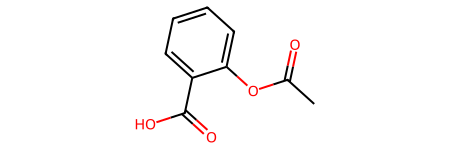

In [5]:
# Estructura 2D o grafo molecular de la aspirina
aspirin = AllChem.MolFromSmiles('O=C(C)Oc1ccccc1C(=O)O')
aspirin

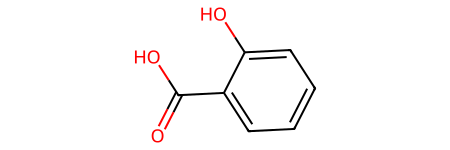

In [6]:
# Estructura 2D o grafo molecular del ácido salicílico
salicylic_acid = AllChem.MolFromSmiles('O=C(O)c1ccccc1O')
salicylic_acid

In [7]:
# Obteniendo los Fingerprints Morgan de aspirina y ácido salicílico
# almacenar el índice de bits ON
bit_asp = {}
bit_sal = {}
aspirin_fp = AllChem.GetMorganFingerprintAsBitVect(aspirin, 2, nBits=2048, bitInfo=bit_asp)
salicylic_acid_fp = AllChem.GetMorganFingerprintAsBitVect(salicylic_acid, 2, nBits=2048, bitInfo=bit_sal)

[14:13:56] DEPRECATION WARNING: please use MorganGenerator
[14:13:56] DEPRECATION WARNING: please use MorganGenerator


In [8]:
print("Salicylic acid:", sorted(set(salicylic_acid_fp.GetOnBits())))
print("Aspirin", sorted(set(aspirin_fp.GetOnBits())))

Salicylic acid: [389, 456, 650, 807, 1047, 1088, 1199, 1211, 1380, 1447, 1519, 1602, 1607, 1750, 1831, 1873, 1917, 1991]
Aspirin [389, 456, 650, 695, 807, 909, 1017, 1035, 1047, 1057, 1088, 1199, 1380, 1410, 1447, 1468, 1616, 1729, 1750, 1775, 1873, 1917, 1970, 1991]


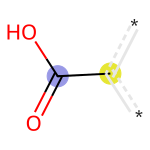

In [9]:
Draw.DrawMorganBit(salicylic_acid, 456, bit_sal)

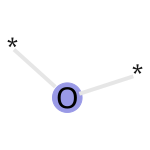

In [10]:
Draw.DrawMorganBit(aspirin, 695, bit_asp)

Vamos a buscar los bits ON que se encuentran tanto en la aspirina como en el ácido salcílico

In [11]:
intersection = set(salicylic_acid_fp.GetOnBits()) & set(aspirin_fp.GetOnBits())
print("intersectan:", intersection)
print("¿Cuántos bits intersectan?:", len(intersection))

intersectan: {1088, 1380, 389, 807, 456, 1447, 650, 1991, 1199, 1873, 1750, 1047, 1917}
¿Cuántos bits intersectan?: 13


In [12]:
Union = set(salicylic_acid_fp.GetOnBits()) | set(aspirin_fp.GetOnBits())
print("Conjunto unión:", Union)
print("¿Cúantos bits forman el conjunto unión?:", len(Union))

Conjunto unión: {1410, 389, 650, 1035, 909, 1047, 1057, 807, 1447, 1831, 1199, 1970, 695, 1211, 1468, 1088, 1729, 1602, 1607, 456, 1991, 1616, 1873, 1750, 1380, 1519, 1775, 1017, 1917}
¿Cúantos bits forman el conjunto unión?: 29


El coeficiente de Tanimoto es el número de bits ON en la intersección de dos conjuntos dividido por su unión


In [13]:
13/29

0.4482758620689655

In [14]:
print("Coeficiente de Tanimoto: ", len(intersection)/len(Union)) # 13/29

Coeficiente de Tanimoto:  0.4482758620689655


# Similitud Química con RDKit


In [15]:
# Calculando el coeficiente de Tanimoto con RDKit
DataStructs.FingerprintSimilarity(aspirin_fp, salicylic_acid_fp, metric=DataStructs.TanimotoSimilarity)

0.4482758620689655

In [16]:
print("TanimotoSimilarity",DataStructs.FingerprintSimilarity(aspirin_fp, salicylic_acid_fp, metric=DataStructs.TanimotoSimilarity))
print("DiceSimilarity", DataStructs.FingerprintSimilarity(aspirin_fp, salicylic_acid_fp, metric=DataStructs.DiceSimilarity))
print("CosineSimilarity",DataStructs.FingerprintSimilarity(aspirin_fp, salicylic_acid_fp, metric=DataStructs.CosineSimilarity))

# for more information, visit:
# https://github.com/rdkit/rdkit-orig/blob/master/rdkit/DataStructs/__init__.py

TanimotoSimilarity 0.4482758620689655
DiceSimilarity 0.6190476190476191
CosineSimilarity 0.6254627916220946


#Búsqueda de compuestos similares a un compuesto específico (query)

In [17]:
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator

# --- Using MorganGenerator (does not directly populate bitInfo) ---
# Initialize the Morgan fingerprint generator
morgan_gen = GetMorganGenerator(radius=2, fpSize=4096)

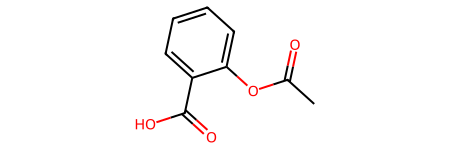

In [18]:
# Encontremos compuestos similares a aspirina
query = AllChem.MolFromSmiles('O=C(C)Oc1ccccc1C(=O)O')#'O=C(C)Oc1ccccc1C(=O)O' aspirin
query_fps = morgan_gen.GetFingerprint(query)
# query_fps = AllChem.GetMorganFingerprintAsBitVect(query, 2, nBits=4096) #C[C@@H](C1=CC2=C(C=C1)C=C(C=C2)OC)C(=O)O'
query

In [19]:
# Calcular las huellas dactilares de todos los compuestos (total 2904)
# all_Mfpts = [AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=4096) for mol in dataset.Structure]
all_Mfpts = [morgan_gen.GetFingerprint(mol) for mol in dataset.Structure]
len(all_Mfpts)

2904

In [20]:
# Calculando el coeficiente de Tanimoto del compuesto de consulta (query) frente a cada uno de los compuestos en el conjunto de datos
# los coloca en la lista
Tanimoto_similarity = [DataStructs.FingerprintSimilarity(query_fps, x, metric=DataStructs.TanimotoSimilarity) for x in all_Mfpts]

In [21]:
# Coloca los valores del coeficiente de Tanimoto en el dataframe
dataset["tanimoto_values"] = Tanimoto_similarity

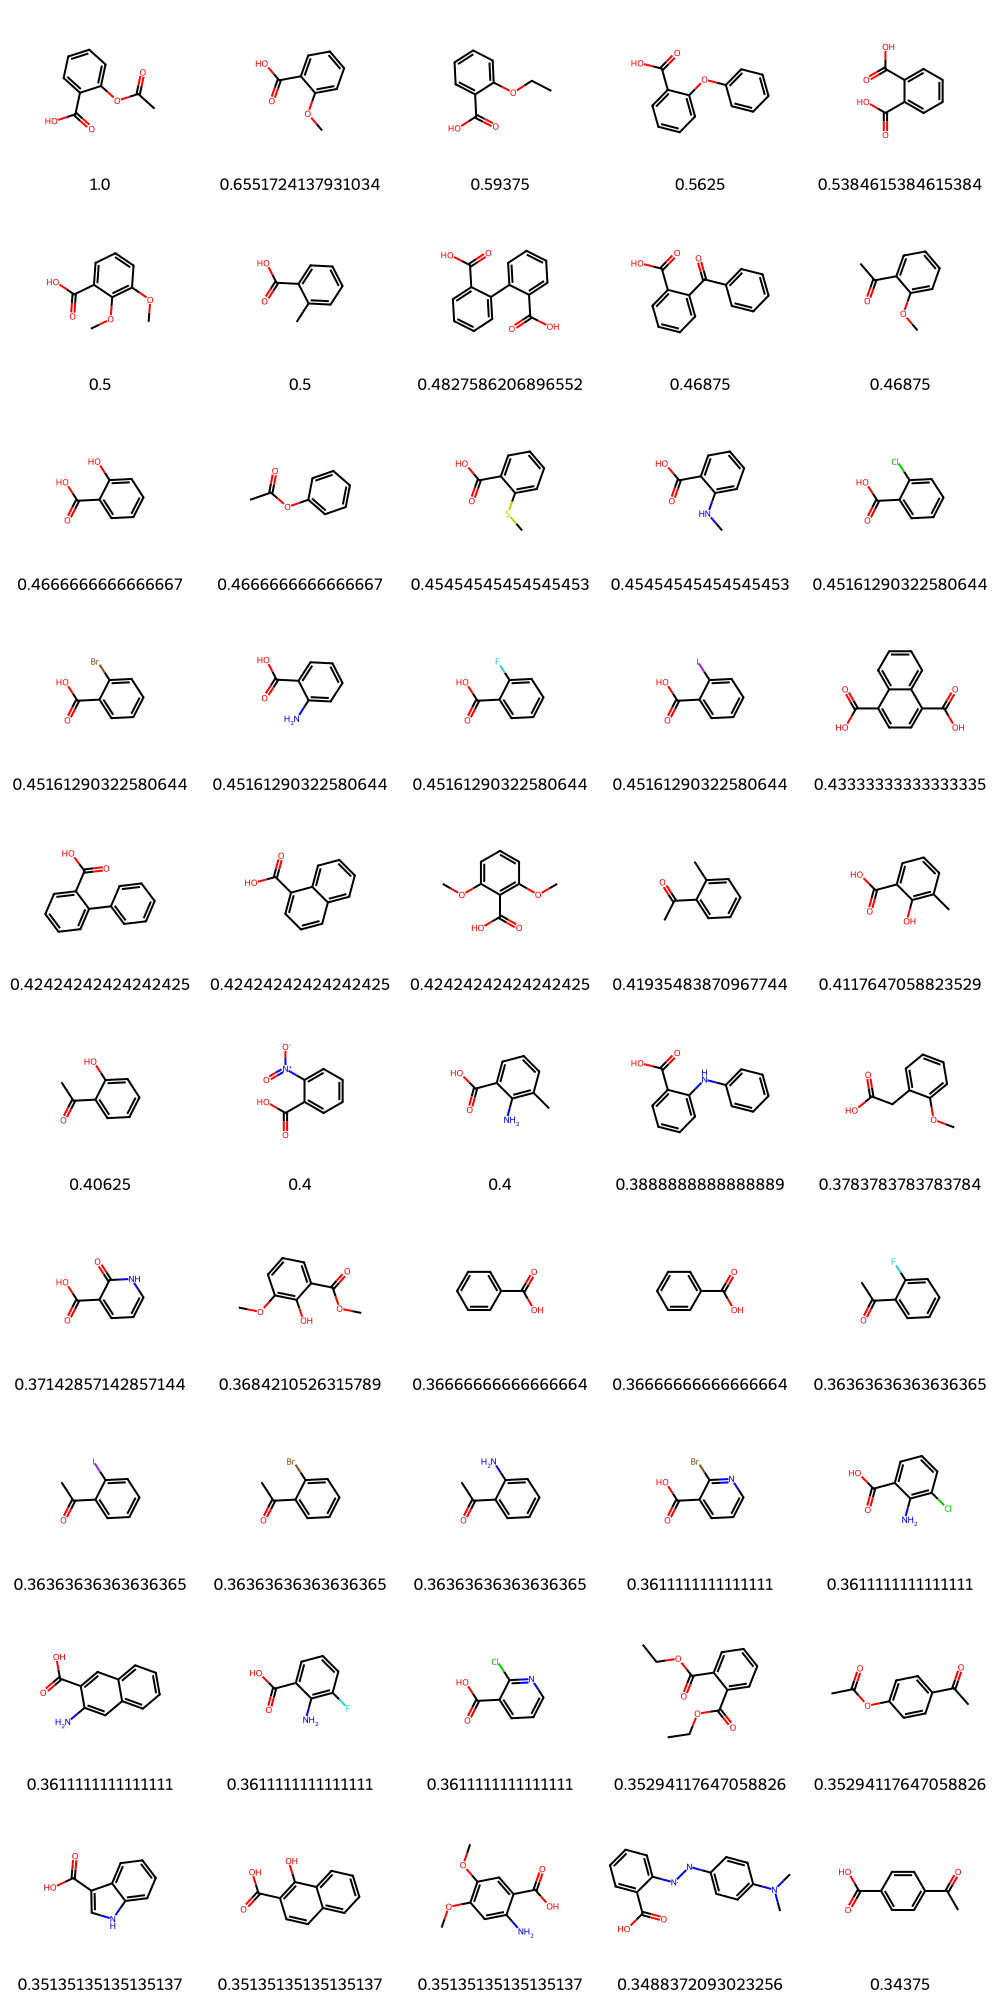

In [22]:
# Ordena los valores del coeficiente de Tanimoto en orden decreciente
dataset_sorted = dataset.sort_values(['tanimoto_values'],ascending=False)
# Mostrar estructuras y valores de coeficientes de Tanimoto.
Draw.MolsToGridImage([x for x in dataset_sorted["Structure"]][:50], maxMols=100,
                     legends=[str(x) for x in dataset_sorted.tanimoto_values], subImgSize=(200,200), molsPerRow=5)

In [23]:
dataset_sorted.shape

(2904, 4)

In [24]:
dataset_sorted.head(10)

,SMILES,Energygap,Structure,tanimoto_values
1339,CC(=O)Oc1ccccc1C(=O)O,194.030175,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db52730>,1.000000
2518,COc1ccccc1C(=O)O,177.605755,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db72f80>,0.655172
2504,CCOc1ccccc1C(=O)O,177.259370,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db72960>,0.593750
1226,OC(=O)c1ccccc1Oc1ccccc1,170.710058,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db4f530>,0.562500
2387,OC(=O)c1ccccc1C(=O)O,174.361533,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db6f5a0>,0.538462
2726,COc1cccc(C(=O)O)c1OC,167.069879,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db78ba0>,0.500000
2728,Cc1ccccc1C(=O)O,187.182170,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db78c80>,0.500000
2606,OC(=O)c1ccccc1c1ccccc1C(=O)O,169.436215,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db75690>,0.482759
1014,OC(=O)c1ccccc1C(=O)c1ccccc1,172.109404,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db497e0>,0.468750
1080,COc1ccccc1C(=O)C,167.960314,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db4b4c0>,0.468750


In [25]:
# Podemos usar un valor umbral para filtrar compuestos.
s = dataset_sorted[dataset_sorted['tanimoto_values'] >= 0.4]
s.shape

(28, 4)

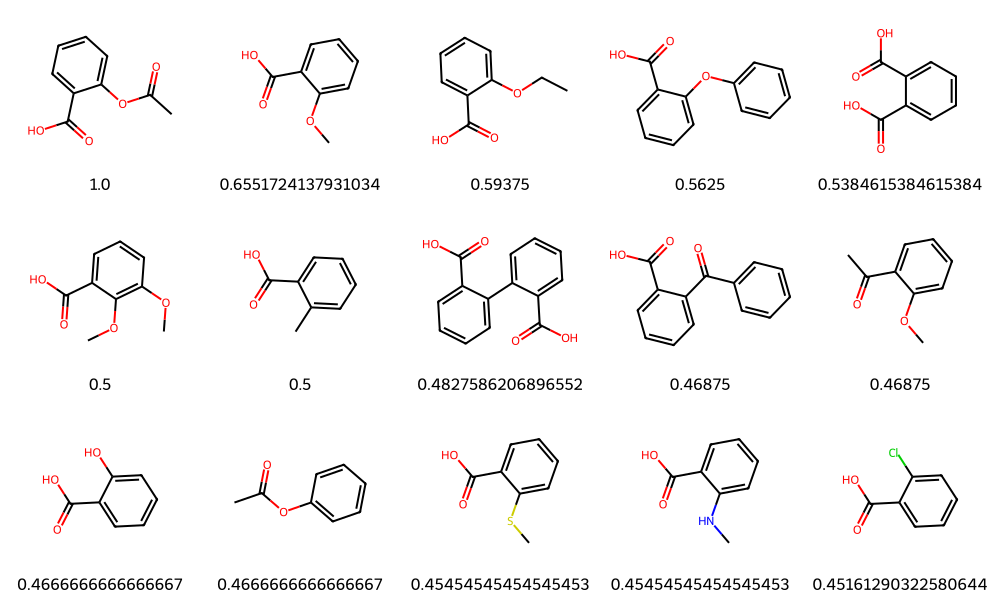

In [26]:
# Mostrar estructuras y valores de coeficientes de Tanimoto.
Draw.MolsToGridImage([x for x in s["Structure"]][:15], maxMols=100,
                     legends=[str(x) for x in s.tanimoto_values], subImgSize=(200,200), molsPerRow=5)

# Calculo de Similitud molecular de manera matricial

In [27]:
# Usemos 20 filas de datos para calcular el coeficiente de Tanimoto en forma matricial
dataset_matrix = dataset[:20]

In [28]:
# Calcule las huellas digitales de Morgan y guárdelas en una lista
fpts_list = []

for mol in dataset_matrix['Structure']:
    fp = morgan_gen.GetFingerprint(mol)
    fpts_list.append(fp)

# colocar la lista de huellas digitales en el marco de datos
dataset_matrix['m_fpt2']= fpts_list

#----------------------------------------------
for ind in tqdm(dataset_matrix.index):
    fp1 = dataset_matrix.at[ind,'m_fpt2']
    col_name = dataset_matrix.at[ind,'Structure']
    simlist = []

    for mol in dataset_matrix.Structure:
        fp = morgan_gen.GetFingerprint(mol)
        sim =DataStructs.TanimotoSimilarity(fp1, fp)
        simlist.append(sim)
    dataset_matrix[col_name] = simlist

100%|██████████| 20/20 [00:00<00:00, 696.00it/s]


In [29]:
# elimine algunas columnas para una mejor visualización
dataset_new = dataset_matrix.drop(['SMILES','Energygap','tanimoto_values','m_fpt2'], axis=1)

# Mostrar 10 filas y columnas del marco de datos
dataset_20 =  dataset_new.iloc[:15,:15] #Iloc es un método utilizado para seleccionar filas y columnas de un DataFrame
                                       #mediante indexación basada en números enteros.
                                       #Es una abreviatura de "ubicación de números enteros" y
                                       #es similar a la indexación utilizada en las matrices NumPy.

# Resalte las puntuaciones de similitud de Tanimoto con coloración contextual
color_map = sn.light_palette("orange", as_cmap=True)
gradient_color = dataset_20.style.background_gradient(cmap=color_map)
gradient_color

,Structure,,,,,,,,,,,,,,
0,,1.000000,0.000000,0.094340,0.103448,0.027027,0.000000,0.083333,0.000000,0.129032,0.074074,0.071429,0.000000,0.043478,0.156250
1,,0.000000,1.000000,0.137255,0.032258,0.085714,0.040000,0.054054,0.034483,0.000000,0.000000,0.090909,0.269231,0.043478,0.000000
2,,0.094340,0.137255,1.000000,0.094340,0.066667,0.019608,0.101695,0.018182,0.129630,0.037736,0.162162,0.113208,0.041667,0.067797
3,,0.103448,0.032258,0.094340,1.000000,0.000000,0.000000,0.258065,0.000000,0.093750,0.074074,0.071429,0.031250,0.000000,0.088235
4,,0.027027,0.085714,0.066667,0.000000,1.000000,0.103448,0.000000,0.028571,0.025000,0.000000,0.047619,0.114286,0.071429,0.023810
5,,0.000000,0.040000,0.019608,0.000000,0.103448,1.000000,0.000000,0.043478,0.000000,0.000000,0.018868,0.080000,0.000000,0.000000
6,,0.083333,0.054054,0.101695,0.258065,0.000000,0.000000,1.000000,0.027778,0.076923,0.058824,0.080645,0.025641,0.000000,0.073171
7,,0.000000,0.034483,0.018182,0.000000,0.028571,0.043478,0.027778,1.000000,0.000000,0.000000,0.054545,0.033333,0.000000,0.000000
8,,0.129032,0.000000,0.129630,0.093750,0.025000,0.000000,0.076923,0.000000,1.000000,0.066667,0.125000,0.000000,0.080000,0.111111
9,,0.074074,0.000000,0.037736,0.074074,0.000000,0.000000,0.058824,0.000000,0.066667,1.000000,0.036364,0.000000,0.000000,0.062500


# Calculo de similitud molecular de manera matricial con umbral

In [30]:
# Usemos 20 filas de datos para calcular el coeficiente de Tanimoto en forma matricial
dataset_matrix_s =s
dataset_matrix_s

,SMILES,Energygap,Structure,tanimoto_values
1339,CC(=O)Oc1ccccc1C(=O)O,194.030175,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db52730>,1.000000
2518,COc1ccccc1C(=O)O,177.605755,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db72f80>,0.655172
2504,CCOc1ccccc1C(=O)O,177.259370,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db72960>,0.593750
1226,OC(=O)c1ccccc1Oc1ccccc1,170.710058,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db4f530>,0.562500
2387,OC(=O)c1ccccc1C(=O)O,174.361533,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db6f5a0>,0.538462
2726,COc1cccc(C(=O)O)c1OC,167.069879,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db78ba0>,0.500000
2728,Cc1ccccc1C(=O)O,187.182170,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db78c80>,0.500000
2606,OC(=O)c1ccccc1c1ccccc1C(=O)O,169.436215,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db75690>,0.482759
1014,OC(=O)c1ccccc1C(=O)c1ccccc1,172.109404,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db497e0>,0.468750
1080,COc1ccccc1C(=O)C,167.960314,<rdkit.Chem.rdchem.Mol object at 0x7f4b5db4b4c0>,0.468750


In [31]:
# Calcule las huellas digitales de Morgan y guárdelas en una lista
fpts_list_s = []

for mol in dataset_matrix_s['Structure']:
    fp_s = morgan_gen.GetFingerprint(mol)
    fpts_list_s.append(fp_s)

# colocar la lista de huellas digitales en el marco de datos
dataset_matrix_s['m_fpt2']= fpts_list_s

#----------------------------------------------
for ind in tqdm(dataset_matrix_s.index):
    fp1_s = dataset_matrix_s.at[ind,'m_fpt2']
    col_name_s = dataset_matrix_s.at[ind,'Structure']
    simlist_s = []

    for mol in dataset_matrix_s.Structure:
        fp_s = morgan_gen.GetFingerprint(mol)
        sim_s =DataStructs.TanimotoSimilarity(fp1_s, fp_s)
        simlist_s.append(sim_s)
    dataset_matrix_s[col_name_s] = simlist_s

100%|██████████| 28/28 [00:00<00:00, 637.06it/s]


In [32]:
# elimine algunas columnas para una mejor visualización
dataset_new_s = dataset_matrix_s.drop(['SMILES','Energygap','tanimoto_values','m_fpt2'], axis=1)

# Mostrar 10 filas y columnas del marco de datos
dataset_20_s =  dataset_new_s.iloc[:20,:20] #Iloc es un método utilizado para seleccionar filas y columnas de un DataFrame
                                       #mediante indexación basada en números enteros.
                                       #Es una abreviatura de "ubicación de números enteros" y
                                       #es similar a la indexación utilizada en las matrices NumPy.

# Resalte las puntuaciones de similitud de Tanimoto con coloración contextual
color_map_s = sn.light_palette("orange", as_cmap=True)
gradient_color_s = dataset_20_s.style.background_gradient(cmap=color_map_s)
gradient_color_s

,Structure,,,,,,,,,,,,,,,,,,,
1339,,1.000000,0.655172,0.593750,0.562500,0.538462,0.500000,0.500000,0.482759,0.468750,0.468750,0.466667,0.466667,0.454545,0.454545,0.451613,0.451613,0.451613,0.451613,0.451613
2518,,0.655172,1.000000,0.633333,0.600000,0.583333,0.689655,0.535714,0.518519,0.451613,0.666667,0.500000,0.312500,0.483871,0.483871,0.482759,0.482759,0.482759,0.482759,0.482759
2504,,0.593750,0.633333,1.000000,0.545455,0.518519,0.485714,0.483871,0.466667,0.411765,0.411765,0.451613,0.285714,0.441176,0.441176,0.437500,0.437500,0.437500,0.437500,0.437500
1226,,0.562500,0.600000,0.545455,1.000000,0.538462,0.457143,0.451613,0.482759,0.468750,0.382353,0.466667,0.375000,0.411765,0.411765,0.451613,0.451613,0.451613,0.451613,0.451613
2387,,0.538462,0.583333,0.518519,0.538462,1.000000,0.464286,0.666667,0.736842,0.681818,0.370370,0.700000,0.307692,0.583333,0.583333,0.666667,0.666667,0.666667,0.666667,0.666667
2726,,0.500000,0.689655,0.485714,0.457143,0.464286,1.000000,0.437500,0.419355,0.371429,0.500000,0.406250,0.250000,0.400000,0.400000,0.393939,0.393939,0.393939,0.393939,0.393939
2728,,0.500000,0.535714,0.483871,0.451613,0.666667,0.437500,1.000000,0.583333,0.500000,0.354839,0.560000,0.300000,0.535714,0.535714,0.538462,0.538462,0.538462,0.538462,0.538462
2606,,0.482759,0.518519,0.466667,0.482759,0.736842,0.419355,0.583333,1.000000,0.538462,0.333333,0.608696,0.275862,0.518519,0.518519,0.583333,0.583333,0.583333,0.583333,0.583333
1014,,0.468750,0.451613,0.411765,0.468750,0.681818,0.371429,0.500000,0.538462,1.000000,0.294118,0.518519,0.322581,0.451613,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
1080,,0.468750,0.666667,0.411765,0.382353,0.370370,0.500000,0.354839,0.333333,0.294118,1.000000,0.322581,0.366667,0.323529,0.323529,0.312500,0.312500,0.312500,0.312500,0.312500


<div style="background-color:lightgreen; border-style: dotted;border-color: yellow;text-align:center;color:blue;font-size:20px;border-radius: 50px;padding: 20px 20px;"><strong> Tomado originalmente de
Gashaw M. Goshu, Ph.D. in Chemistry </strong></div> https://www.youtube.com/watch?v=-oHqQBUyrQ0 , adaptado por el Dr. Erick Correa para el curso de Desarrollo de Fármacos Asistido por Computadora Laboratorio de Síntesis de Fármacos L-9, F.E.S. Zaragoza UNAM

